# Cafe Sales Data Analysis

## Project Overview

This project focuses on cleaning and performing Exploratory Data Analysis (EDA) on a Cafe Sales dataset using Python.

The dataset contains 10,000 transaction records with information about purchased items, quantities, prices, payment methods, locations and transaction dates.

The main objective is to understand the dataset, identify inconsistencies, clean the data and explore sales patterns through visualisations.

## Libraries Used

- Pandas
- NumPy
- Matplotlib

## 1. Importing Libraries and Loading Dataset

First, we import the required Python libraries and load the cafe sales dataset using Pandas.

The dataset is stored in a DataFrame named `df`.

In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('dirty_cafe_sales.csv')

## 2. Initial Data Inspection

Before cleaning the dataset, we examine its structure and contents.

The following operations help us understand:

- The first few records in the dataset.
- The number of rows and columns.
- Data types and non-null values.
- Basic statistical information.
- Missing values and duplicate records.

In [32]:
# Head of the dataset
print(df.head())

# Find the number of rows and columns
print(df.shape)

# Find data types and non-null values
df.info()

# Basic statistical summary
print(df.describe())

# Find missing and duplicate values
print("Missing values :", df.isnull().sum())
print("Duplicate rows :", df.duplicated().sum())

  Transaction ID    Item Quantity Price Per Unit Total Spent  Payment Method  \
0    TXN_1961373  Coffee        2            2.0         4.0     Credit Card   
1    TXN_4977031    Cake        4            3.0        12.0            Cash   
2    TXN_4271903  Cookie        4            1.0       ERROR     Credit Card   
3    TXN_7034554   Salad        2            5.0        10.0         UNKNOWN   
4    TXN_3160411  Coffee        2            2.0         4.0  Digital Wallet   

   Location Transaction Date  
0  Takeaway       2023-09-08  
1  In-store       2023-05-16  
2  In-store       2023-07-19  
3   UNKNOWN       2023-04-27  
4  In-store       2023-06-11  
(10000, 8)
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    10000 non-null  str  
 1   Item              9667 non-null   str  
 2   Quantity          9862 non-null   str  
 

## 3. Data Cleaning

In this section, we clean the dataset and prepare it for analysis.

The following operations are performed:

1. Create a copy of the original dataset.
2. Remove duplicate records.
3. Remove unnecessary whitespaces from column names and string values.
4. Examine categorical values and identify inconsistencies.
5. Identify numerical and categorical columns.
6. Replace invalid placeholder values such as ERROR and UNKNOWN with missing values.
7. Convert numerical columns into appropriate data types.
8. Convert the Transaction Date column into datetime format.

In [33]:
df_clean = df.copy()

# Remove duplicate values
df_clean = df_clean.drop_duplicates()

# Remove spaces in column names
df_clean.columns = df_clean.columns.str.strip()

# Remove spaces from string values
for col in df_clean.select_dtypes(include='object').columns:
    df_clean[col] = df_clean[col].str.strip()

print("Updated shape :", df_clean.shape)

# Examine categorical values
for col in df_clean.select_dtypes(include='object').columns:
    print("\n", col)
    print(df_clean[col].value_counts(dropna=False).head(15))

# Numerical columns
print("Numerical columns :")
print(df_clean.select_dtypes(include=np.number).columns.tolist())

# Categorical columns
print("Categorical columns :")
print(df_clean.select_dtypes(include="object").columns.tolist())

# Replace invalid placeholder values with NaN
df_clean = df_clean.replace(
    ['ERROR', 'UNKNOWN', ''],
    np.nan
)

# Check missing values again
print(df_clean.isnull().sum())

# Convert numerical columns from object to numbers
numeric_columns = [
    'Quantity',
    'Price Per Unit',
    'Total Spent'
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors='coerce'
    )

# Convert Transaction Date
df_clean['Transaction Date'] = pd.to_datetime(
    df_clean['Transaction Date'],
    errors='coerce'
)

# Check updated data types
df_clean.info()

Updated shape : (10000, 8)

 Transaction ID
Transaction ID
TXN_1961373    1
TXN_4977031    1
TXN_4271903    1
TXN_7034554    1
TXN_3160411    1
TXN_2602893    1
TXN_4433211    1
TXN_6699534    1
TXN_4717867    1
TXN_2064365    1
TXN_2548360    1
TXN_3051279    1
TXN_7619095    1
TXN_9437049    1
TXN_8915701    1
Name: count, dtype: int64

 Item
Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
UNKNOWN      344
NaN          333
ERROR        292
Name: count, dtype: int64

 Quantity
Quantity
5          2013
2          1974
4          1863
3          1849
1          1822
UNKNOWN     171
ERROR       170
NaN         138
Name: count, dtype: int64

 Price Per Unit
Price Per Unit
3.0        2429
4.0        2331
2.0        1227
5.0        1204
1.0        1143
1.5        1133
ERROR       190
NaN         179
UNKNOWN     164
Name: count, dtype: int64

 Total Spent
Total Spent
6.0     979
12.0    939
3.0     9

/var/folders/96/3l2_5349419fv1wyn6193m3w0000gn/T/ipykernel_14848/3714065241.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_clean.select_dtypes(include='object').columns:
/var/folders/96/3l2_5349419fv1wyn6193m3w0000gn/T/ipykernel_14848/3714065241.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pa

## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand patterns, distributions and relationships within the cleaned dataset.

Matplotlib is used to create different visualisations and explore cafe sales data.

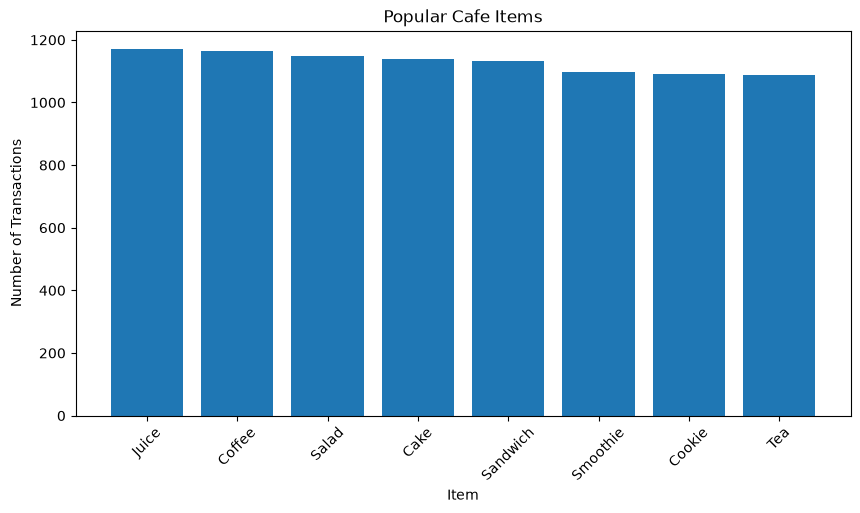

In [34]:
item_counts = df_clean['Item'].value_counts()

plt.figure(figsize=(10,5))
plt.bar(item_counts.index, item_counts.values)

plt.title("Popular Cafe Items")
plt.xlabel("Item")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)

plt.show()

### 4.2 Quantity Distribution

A histogram is used to examine the distribution of quantities purchased in individual transactions.

It helps us understand how frequently customers purchase different quantities.

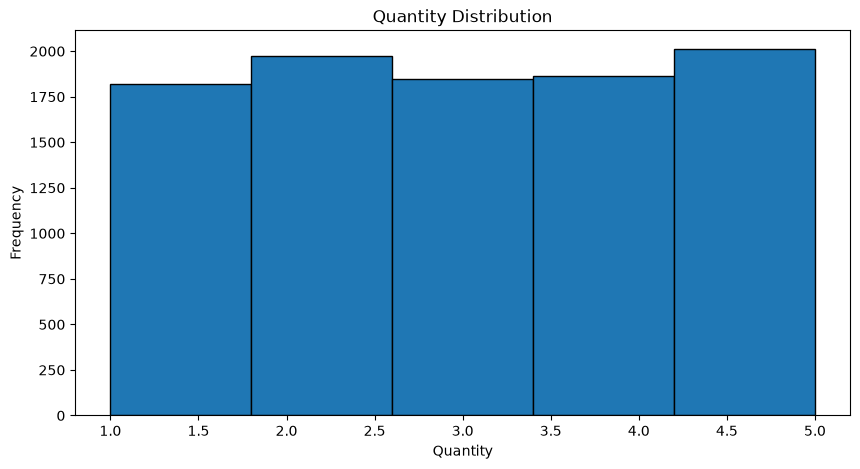

In [35]:
plt.figure(figsize=(10,5))

plt.hist(
    df_clean['Quantity'].dropna(),
    bins=5,
    edgecolor='black'
)

plt.title("Quantity Distribution")
plt.xlabel("Quantity")
plt.ylabel("Frequency")

plt.show()

### 4.3 Payment Method Distribution

A pie chart is used to analyse the distribution of payment methods.

It shows the percentage contribution of each payment method among transactions with known payment information.

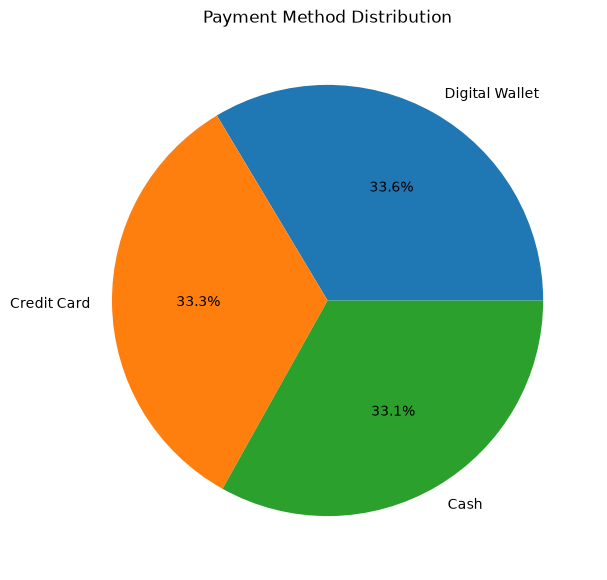

In [36]:
payment_counts = df_clean['Payment Method'].value_counts()

plt.figure(figsize=(10,7))

plt.pie(
    payment_counts.values,
    labels=payment_counts.index,
    autopct='%1.1f%%'
)

plt.title("Payment Method Distribution")
plt.show()

### 4.4 Total Spending by Price Per Unit

A boxplot is used to compare the distribution of total spending across different unit prices.

It helps identify the median spending, variation in transactions and potential outliers.

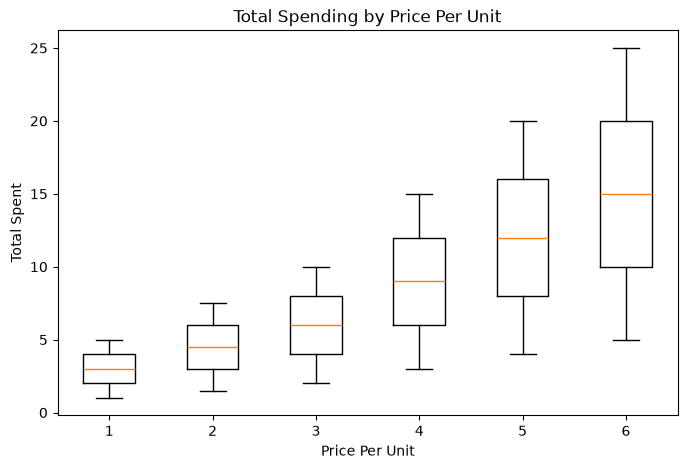

In [37]:
prices = sorted(df_clean['Price Per Unit'].dropna().unique())

spent = []

for price in prices:
    spent.append(
        df_clean[df_clean['Price Per Unit'] == price]['Total Spent'].dropna()
    )

plt.figure(figsize=(8,5))

plt.boxplot(spent, label=prices)

plt.title("Total Spending by Price Per Unit")
plt.xlabel("Price Per Unit")
plt.ylabel("Total Spent")

plt.show()

### 4.5 Price Per Unit vs Total Spent

A scatter plot is used to examine the relationship between the price per unit and the total amount spent in a transaction.

It helps explore how transaction spending varies with item prices.

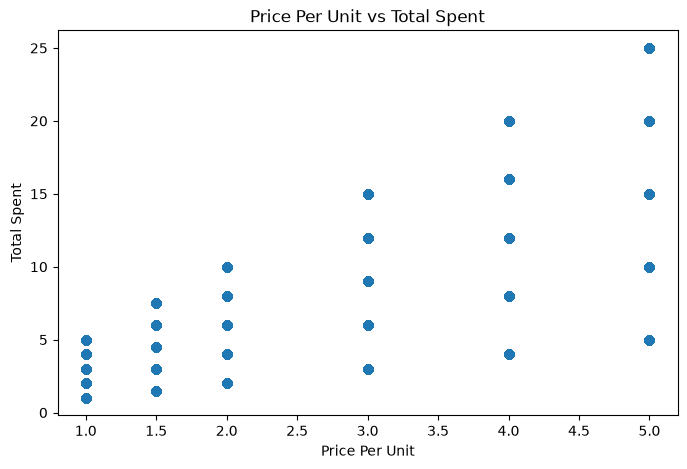

In [38]:
plt.figure(figsize=(8,5))

plt.scatter(
    df_clean['Price Per Unit'],
    df_clean['Total Spent']
)

plt.title("Price Per Unit vs Total Spent")
plt.xlabel("Price Per Unit")
plt.ylabel("Total Spent")

plt.show()

### 4.6 Payment Methods by Location

A stacked bar chart is used to compare payment methods across different order locations.

It helps identify differences in payment preferences between In-store and Takeaway transactions.

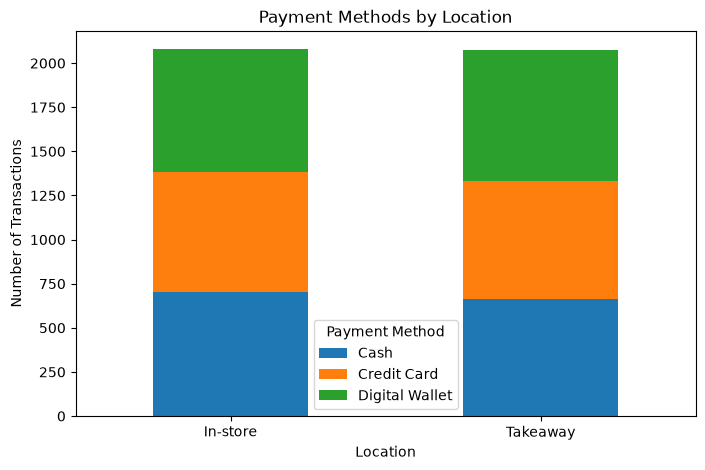

In [39]:
payment_location = pd.crosstab(
    df_clean['Location'],
    df_clean['Payment Method']
)

payment_location.plot(
    kind='bar',
    stacked=True,
    figsize=(8,5)
)

plt.title("Payment Methods by Location")
plt.xlabel("Location")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=0)
plt.legend(title="Payment Method")

plt.show()

## 5. Conclusion

Through this project, the Cafe Sales dataset was explored and cleaned using Python.

The data cleaning process helped identify and handle missing values, inconsistent entries and incorrect data types.

Different visualisations were created to understand:

- Popular cafe items.
- Distribution of purchase quantities.
- Payment method preferences.
- Spending patterns across different item prices.
- Relationship between unit price and total spending.
- Payment methods across different order locations.

This project demonstrates the importance of data cleaning and Exploratory Data Analysis in understanding raw datasets and extracting meaningful information.